# One small CNN for all three tasks: does it solve them, and do attention effects emerge?

Goal: one network, trained from scratch, that solves the Posner task, visual search and contextual cueing (accuracy well above chance on each), and then: does it show the attention effects (better on valid than invalid cues, on small than large set sizes, on old than new layouts), and which units carry each task (lesions)?

**Network** (`smallcnn/model.py`, from the paper's `One_Network_All_Three_Tasks5VS.ipynb`, cell 91): Conv(12, 3×3, stride 2) → Conv(14, 3×3, stride 2) → Conv(18, 2×2) → BatchNorm → Dense(600) → 6 classes (2 per task); one grey channel, 224 × 224, 0–1. Adam, batch 16, 30 epochs.

**Groups** (seeds 0–2 each, the v2 joint group seeds 0–9):

- *joint, fixed noise*: all three tasks; noise drawn once per training image, as in the paper.
- *joint, fresh noise*: all three tasks; new noise every epoch.
- *Posner only*: the same network trained on Posner alone (control: does joint training remove the cueing effect?).
- *v2* (fresh noise): learning rate 0.0003 instead of 0.001 (far fewer dead Dense units), and for the joint group search noise 0.12 instead of 0.04 (search off the ceiling, so a set-size effect can show). The v2 joint networks are also tested at search noise 0.12.

**Measures**: per-task accuracy and AUC (does it solve the task?), the effects as AUC differences with bootstrap CIs; `neuron_cueing.py` for single units; `lesion.py --decision within` (Dense) and `layer_lesions.py` (conv layers and Dense).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from data import TASKS
from metrics import separation, task_metrics, within_task

RUNS = Path("..") / "runs"
GROUPS = {"joint, fixed noise": "smallcnn/joint_fixed_seed{}",
          "joint, fresh noise": "smallcnn/joint_fresh_seed{}",
          "Posner only, fixed noise": "smallcnn/posner_fixed_seed{}",
          "Posner only, fresh noise": "smallcnn/posner_fresh_seed{}",
          "joint v2 (lr 0.0003, search noise 0.12)": "smallcnn/joint_fresh_v2_seed{}",
          "Posner only v2 (lr 0.0003)": "smallcnn/posner_fresh_v2_seed{}"}
run = {g: {s: RUNS / p.format(s) for s in range(10) if (RUNS / p.format(s) / "test_predictions.csv").exists()}
       for g, p in GROUPS.items()}
run = {g: r for g, r in run.items() if r}
POSNER_ONLY = [g for g in run if "Posner only" in g]
pred = {(g, s): pd.read_csv(r / "test_predictions.csv") for g, rs in run.items() for s, r in rs.items()}
meta = next(iter(pred.values()))
assert all((p.file == meta.file).all() for p in pred.values())  # the bootstrap resamples the same trials for all

EFFECTS = {"posner_cue_effect_auc": "Posner cueing (valid − invalid)",
           "search_set_size_effect_auc": "search set size (1 − 8)",
           "context_effect_auc": "contextual cueing (old − new)"}
TASK_OF = dict(zip(EFFECTS, TASKS))
KEYS = [*EFFECTS, "posner_cue_effect", "posner_hit_valid", "posner_hit_invalid", "posner_false_alarm",
        "posner_valid_auc", "posner_invalid_auc", *(f"{t}_acc" for t in TASKS), *(f"{t}_auc" for t in TASKS)]


def metrics(L, m):
    return {**task_metrics(within_task(L, m.label.to_numpy()), m), **separation(L, m)}


def applies(group, key):
    return group not in POSNER_ONLY or key.startswith("posner")


print({g: list(r) for g, r in run.items()})

{'joint, fixed noise': [0, 1, 2], 'joint, fresh noise': [0, 1, 2], 'Posner only, fixed noise': [0, 1, 2], 'Posner only, fresh noise': [0, 1, 2], 'joint v2 (lr 0.0003, search noise 0.12)': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], 'Posner only v2 (lr 0.0003)': [0, 1, 2]}


## 1. Intact networks: do they solve the tasks, and do the effects appear?

First table: per-task accuracy (the network's own decision; chance 0.5) and AUC (threshold-free: can the outputs separate the two answers at all?). Second table: the effects.
Full test set (8040 trials, each network with its own pixel noise). Brackets: 95 % bootstrap interval of the group mean (1000 resamples of the test trials, stratified by condition cell, the same resamples for every network). Last columns: in how many networks the AUC effect's own interval lies above zero. Posner-only networks are scored on Posner only.

In [2]:
def bootstrap(n_boot=1000, seed=0):
    cells = list(meta.groupby(["set", "label", "validity", "target", "cue"], dropna=False).indices.values())
    logits = {k: p.filter(like="logit_").to_numpy() for k, p in pred.items()}
    rng, out = np.random.default_rng(seed), []
    for b in range(n_boot):
        idx = np.concatenate([rng.choice(c, len(c)) for c in cells])
        m_b = meta.iloc[idx].reset_index(drop=True)
        out += [{"boot": b, "group": g, "seed": s, **{k: v for k, v in metrics(logits[g, s][idx], m_b).items() if k in KEYS}}
                for g, s in logits]
    return pd.DataFrame(out)


full = pd.DataFrame([{"group": g, "seed": s, **{k: v for k, v in metrics(p.filter(like="logit_").to_numpy(), meta).items() if k in KEYS}}
                     for (g, s), p in pred.items()])
boot = bootstrap()
boot_mean = boot.groupby(["boot", "group"])[KEYS].mean()
low, high = boot_mean.groupby("group").quantile(0.025), boot_mean.groupby("group").quantile(0.975)
net_low = boot.groupby(["group", "seed"])[KEYS].quantile(0.025)
mean = full.groupby("group", sort=False)[KEYS].mean()


def cell(g, k, fmt="+.3f"):
    return f"{mean.loc[g, k]:{fmt}} [{low.loc[g, k]:{fmt}}, {high.loc[g, k]:{fmt}}]" if applies(g, k) else ""


display(pd.DataFrame({g: {**{f"{t} accuracy": f"{mean.loc[g, f'{t}_acc']:.3f}" if applies(g, t) else "" for t in TASKS},
                          **{f"{t} AUC": f"{mean.loc[g, f'{t}_auc']:.3f}" if applies(g, t) else "" for t in TASKS}}
                      for g in run}).T)
display(pd.DataFrame({g: {**{name: cell(g, e) for e, name in EFFECTS.items()},
                          **{f"{name}: networks with CI > 0": f"{(net_low.loc[g][e] > 0).sum()}/{len(run[g])}"
                             for e, name in EFFECTS.items() if applies(g, e)}}
                      for g in run}).T.fillna(""))

,posner accuracy,search accuracy,context accuracy,posner AUC,search AUC,context AUC
"joint, fixed noise",0.677,0.756,0.562,0.747,0.831,0.585
"joint, fresh noise",0.773,0.988,0.798,0.864,0.999,0.906
"Posner only, fixed noise",0.712,,,0.777,,
"Posner only, fresh noise",0.783,,,0.873,,
"joint v2 (lr 0.0003, search noise 0.12)",0.781,0.811,0.885,0.873,0.900,0.962
Posner only v2 (lr 0.0003),0.780,,,0.871,,


,Posner cueing (valid − invalid),search set size (1 − 8),contextual cueing (old − new),Posner cueing (valid − invalid): networks with CI > 0,search set size (1 − 8): networks with CI > 0,contextual cueing (old − new): networks with CI > 0
"joint, fixed noise","+0.095 [+0.056, +0.136]","+0.078 [+0.060, +0.097]","+0.016 [-0.012, +0.046]",2/3,3/3,0/3
"joint, fresh noise","+0.089 [+0.052, +0.128]","+0.003 [+0.002, +0.005]","+0.310 [+0.285, +0.337]",3/3,3/3,3/3
"Posner only, fixed noise","+0.076 [+0.037, +0.117]",,,3/3,,
"Posner only, fresh noise","+0.112 [+0.072, +0.158]",,,3/3,,
"joint v2 (lr 0.0003, search noise 0.12)","+0.101 [+0.065, +0.143]","+0.128 [+0.120, +0.136]","+0.133 [+0.118, +0.149]",10/10,10/10,10/10
Posner only v2 (lr 0.0003),"+0.108 [+0.069, +0.154]",,,3/3,,


Posner as the paper measures it (hit rates on target trials; mean of the networks, per network after |)


,posner_hit_valid,posner_hit_invalid,posner_false_alarm,posner_cue_effect,posner_valid_auc,posner_invalid_auc
"joint, fixed noise",0.616 | 0.680 / 0.740 / 0.427,0.433 | 0.500 / 0.480 / 0.320,0.225 | 0.264 / 0.236 / 0.174,0.183 | 0.180 / 0.260 / 0.107,0.767 | 0.781 / 0.826 / 0.695,0.672 | 0.693 / 0.686 / 0.638
"joint, fresh noise",0.787 | 0.833 / 0.765 / 0.765,0.583 | 0.720 / 0.490 / 0.540,0.201 | 0.244 / 0.170 / 0.188,0.204 | 0.113 / 0.275 / 0.225,0.883 | 0.881 / 0.887 / 0.881,0.794 | 0.813 / 0.792 / 0.778
"Posner only, fixed noise",0.708 | 0.728 / 0.682 / 0.713,0.557 | 0.650 / 0.450 / 0.570,0.253 | 0.280 / 0.244 / 0.236,0.151 | 0.078 / 0.232 / 0.143,0.792 | 0.791 / 0.789 / 0.795,0.716 | 0.723 / 0.686 / 0.739
"Posner only, fresh noise",0.806 | 0.777 / 0.812 / 0.828,0.560 | 0.570 / 0.560 / 0.550,0.190 | 0.176 / 0.184 / 0.210,0.246 | 0.208 / 0.252 / 0.277,0.896 | 0.896 / 0.896 / 0.896,0.784 | 0.785 / 0.789 / 0.779
"joint v2 (lr 0.0003, search noise 0.12)",0.815 | 0.807 / 0.785 / 0.790 / 0.835 / 0.890 ...,0.592 | 0.630 / 0.490 / 0.540 / 0.670 / 0.720 ...,0.208 | 0.204 / 0.166 / 0.184 / 0.266 / 0.282 ...,0.224 | 0.177 / 0.295 / 0.250 / 0.165 / 0.170 ...,0.894 | 0.890 / 0.892 / 0.892 / 0.887 / 0.902 ...,0.793 | 0.807 / 0.798 / 0.779 / 0.782 / 0.807 ...
Posner only v2 (lr 0.0003),0.817 | 0.812 / 0.805 / 0.833,0.567 | 0.620 / 0.510 / 0.570,0.207 | 0.200 / 0.180 / 0.240,0.250 | 0.193 / 0.295 / 0.263,0.893 | 0.893 / 0.895 / 0.892,0.785 | 0.793 / 0.786 / 0.777


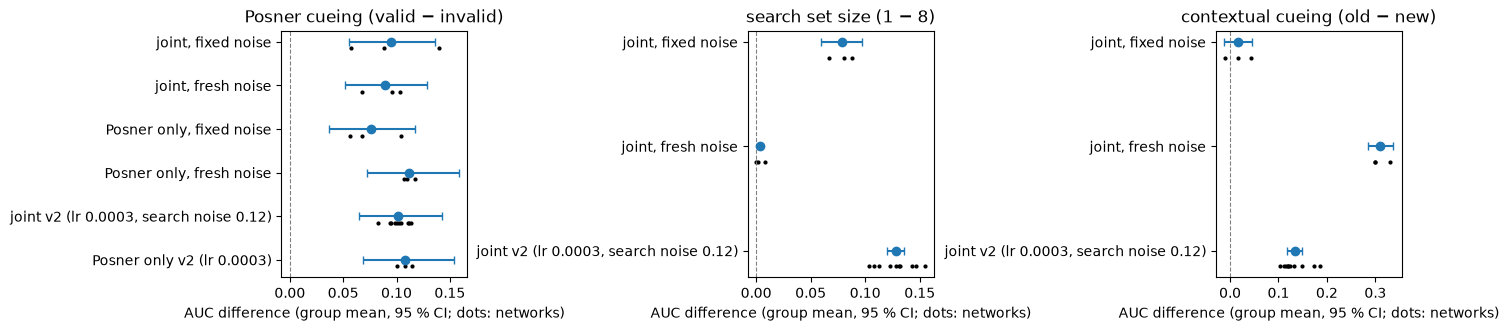

In [3]:
print("Posner as the paper measures it (hit rates on target trials; mean of the networks, per network after |)")
display(pd.DataFrame({g: {k: f"{mean.loc[g, k]:.3f} | " + " / ".join(f"{v:.3f}" for v in full[full.group == g][k])
                          for k in ("posner_hit_valid", "posner_hit_invalid", "posner_false_alarm", "posner_cue_effect",
                                    "posner_valid_auc", "posner_invalid_auc")} for g in run}).T)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), layout="constrained")
for ax, (e, name) in zip(axes, EFFECTS.items()):
    gs = [g for g in run if applies(g, e)]
    y = np.arange(len(gs))
    m = mean.loc[gs, e]
    ax.errorbar(m, y, xerr=[m - low.loc[gs, e], high.loc[gs, e] - m], fmt="o", capsize=3)
    for i, g in enumerate(gs):
        ax.plot(full[full.group == g][e], np.full(len(run[g]), i + 0.15), "k.", ms=4)
    ax.axvline(0, color="grey", lw=0.8, ls="--")
    ax.set(yticks=y, yticklabels=gs, title=name, xlabel="AUC difference (group mean, 95 % CI; dots: networks)")
    ax.invert_yaxis()
plt.show()

**Reading.** AUC is written here as a percentage: the chance that the network rates a random target image above a random no-target image (50 % = guessing, 100 % = perfect). An effect is the gap between two conditions in percentage points.

- **Joint v2 solves all three tasks** in all 10 networks: accuracy Posner 78 %, search 81 %, context 89 % (AUC 87 / 90 / 96 %).
- **All three attention effects appear in 10 out of 10 networks:**
  - Posner cueing: AUC 89 % on valid trials vs 79 % on invalid trials, a gap of +10 points (95 % CI +6.5 to +14). In the paper's measure, the hit rate is 81.5 % valid vs 59 % invalid, with 21 % false alarms.
  - Set size: +13 points (CI +12 to +14) between 1 and 8 items. This is new: at the old search noise the search task was at 99.9 % and the gap was 0.3 points.
  - Contextual cueing: +13 points (CI +12 to +15). This is smaller than the old fresh-noise networks' +31 points because v2 does better on new layouts (accuracy 74–81 % vs about 62 %). Old layouts stay at 98–100 %.
- **Joint training does not remove the Posner effect:** joint v2 +10 points, Posner only v2 +11 points (CIs overlap).
- **Fixed noise (the paper's setup)** memorises the training images: no contextual cueing (+1.6 points, 0 out of 3 networks).

## 2. Neuronal cueing in single Dense units

`neuron_cueing.py`: for every live Dense unit, AUROC(target vs no-target) on valid minus invalid trials, 10 noise draws per test image, bootstrap over clean images, Benjamini–Hochberg at q < 0.05. Counts per network.

The paper (Srivastava et al. 2025, PNAS) reports 56 %, but its code measures differently: AUROC with the cue at the target minus AUROC with **no cue** (e.g. `Posner_neutral.ipynb`), and a unit counts when that difference exceeds 0.05 (a fixed cut-off, no test). Our test set had no cue-free images, so `neuron_cueing.py` makes them by painting the cue box over in the background grey (every Posner image has exactly one box, 320 pixels at grey 179), with the same noise. The networks never saw a cue-free image in training. "paper rule" columns: units over the cut-off, out of the live and out of the target-tuned units.

In [4]:
rows = []
for g, rs in run.items():
    for s, r in rs.items():
        u = pd.read_csv(r / "neuron_cueing" / "units.csv")
        pop = pd.read_csv(r / "neuron_cueing" / "population.csv").set_index(["trials", "measure"])
        for trials, d in u.groupby("trials", sort=False):
            units = d[d.live & (d.unit != "output")]
            tuned = units[units.tuning != "untuned"]
            o = d[d.unit == "output"].iloc[0]
            out = pop.loc[(trials, "output z: cueing effect")]
            p = pop.loc[(trials, "tuned units: mean cueing effect x tuning sign")]
            rows.append({"group": g, "seed": s, "trials": trials, "live units": len(units),
                         "tuned (T+/T−)": f"{(units.tuning == 'T+').sum()}/{(units.tuning == 'T-').sum()}",
                         "valid > invalid": (units.cueing == "valid > invalid").sum(),
                         "valid < invalid": (units.cueing == "valid < invalid").sum(),
                         "% of live units": 100 * units.cueing.notna().mean(),
                         "paper rule: % of live": 100 * units.paper_rule.mean(),
                         "paper rule: tuned": f"{units.paper_rule[tuned.index].sum()}/{len(tuned)}",
                         "output z cueing [95 % CI]": f"{out.estimate:+.3f} [{out.ci_low:+.3f}, {out.ci_high:+.3f}]",
                         "output z valid − no cue (SE)": f"{o.nocue_effect:+.3f} ({o.nocue_effect_se:.3f})",
                         "tuned units, signed mean [95 % CI]": f"{p.estimate:+.3f} [{p.ci_low:+.3f}, {p.ci_high:+.3f}]"})
display(pd.DataFrame(rows).set_index(["trials", "group", "seed"]).sort_index(level=0, sort_remaining=False).round(1))

live units  \
trials   group                                   seed               
all      joint, fixed noise                      0            540   
                                                 1            571   
                                                 2            545   
         joint, fresh noise                      0             81   
                                                 1             75   
                                                 2            121   
         Posner only, fixed noise                0            569   
                                                 1            596   
                                                 2            600   
         Posner only, fresh noise                0            437   
                                                 1            387   
                                                 2            364   
         joint v2 (lr 0.0003, search noise 0.12) 0            328   
                                                 1            312   
                                                 2            412   
                                                 3            261   
                                                 4            297   
                                                 5            296   
                                                 6            346   
                                                 7            320   
                                                 8            253   
                                                 9            420   
         Posner only v2 (lr 0.0003)              0            444   
                                                 1            555   
                                                 2            509   
distinct joint, fixed noise                      0            540   
                                                 1            571   
                                                 2            545   
         joint, fresh noise                      0             81   
                                                 1             75   
                                                 2            121   
         Posner only, fixed noise                0            569   
                                                 1            596   
                                                 2            600   
         Posner only, fresh noise                0            437   
                                                 1            387   
                                                 2            364   
         joint v2 (lr 0.0003, search noise 0.12) 0            328   
                                                 1            312   
                                                 2            412   
                                                 3            261   
                                                 4            297   
                                                 5            296   
                                                 6            346   
                                                 7            320   
                                                 8            253   
                                                 9            420   
         Posner only v2 (lr 0.0003)              0            444   
                                                 1            555   
                                                 2            509   

                                                      tuned (T+/T−)  \
trials   group                                   seed                 
all      joint, fixed noise                      0            27/28   
                                                 1            29/26   
                                                 2             8/15   
         joint, fresh noise                      0              9/5   
                                        

**Reading.**

- **The paper's 56 % is not reproduced.** With the paper's own rule (cue at the target vs no cue, more than 5 points), joint v2 has 2 to 11 units per network: 1–4 % of the live units, or 1–5 % when each clean image counts once. Even among the tuned units it is only 1 to 10 out of 47 to 77.
- **The gap is not a dead-unit artefact any more.** Joint v2 has 253–420 live units on the Posner test trials, vs 75–121 in the old joint, fresh-noise networks, and still only 1–5 % meet the paper rule. Posner-only networks look the same (1–6 %).
- **Most of the cueing is a cost on invalid trials.** At the output, valid vs no cue is only +3 points (uncertainty about ±3), while valid vs invalid is +10 points. The cue barely helps when it is right; it hurts when it is wrong.
- **Our own test** (valid vs invalid, bootstrap, corrected for many tests) finds a significant effect in 6–14 % of live units in joint v2, almost all with valid > invalid. The signed mean over tuned units is +2 to +3.5 points in every network.
- Caveat: the networks never saw a cue-free image in training, so the paper rule's no-cue condition is new to them. Our own test (valid vs invalid) uses only trained-on images and also finds few units. The paper's 56 % may also use a different set of units or trials; I have not found the code line that computes it.

## 3. Dense lesions: task-specific units and the effects

`lesion.py --decision within`, zero lesions; units ranked by Shapley value on one half of the test trials, lesioned on the other half. Top: AUC change of each task when the top 5 % of units for one task's accuracy are removed, against random lesions of the same size (mean of the networks). A diagonal pattern means task-specific units. Bottom: the effects after removing 20 % of the units.

In [5]:
def dense(g):
    return pd.concat([pd.read_csv(r / "lesion_within" / "lesions.csv").assign(seed=s) for s, r in run[g].items()])


for g in run:
    d = dense(g)
    z = d[(d.lesion_mode == "zero") & (d.fraction == 0.05)]
    rnd = z[z.selection == "random"].groupby("seed")[[f"{t}_auc" for t in TASKS]].mean()
    srcs = [t for t in TASKS if applies(g, t)]
    matrix = pd.DataFrame({f"{dst} AUC": {f"top 5 % of {src}": (z[(z.ranking == f"acc_{src}_zero") & (z.selection == "top")]
                                                              .set_index("seed")[f"{dst}_auc"] - rnd[f"{dst}_auc"]).mean()
                                         for src in srcs} for dst in srcs})
    print(f"{g}: AUC change vs random, top 5 % of Dense units (n = {int(z[z.selection == 'top'].n_units.iloc[0])})")
    display(matrix.round(3))

joint, fixed noise: AUC change vs random, top 5 % of Dense units (n = 30)


,posner AUC,search AUC,context AUC
top 5 % of posner,-0.033,-0.003,0.003
top 5 % of search,0.003,-0.214,0.000
top 5 % of context,-0.002,-0.004,-0.003


joint, fresh noise: AUC change vs random, top 5 % of Dense units (n = 30)


,posner AUC,search AUC,context AUC
top 5 % of posner,-0.355,-0.027,0.014
top 5 % of search,0.003,-0.107,0.015
top 5 % of context,0.004,0.010,-0.092


Posner only, fixed noise: AUC change vs random, top 5 % of Dense units (n = 30)


,posner AUC
top 5 % of posner,-0.011


... (2 outputs left out)

joint v2 (lr 0.0003, search noise 0.12): AUC change vs random, top 5 % of Dense units (n = 30)


,posner AUC,search AUC,context AUC
top 5 % of posner,-0.058,-0.001,0.002
top 5 % of search,0.002,-0.145,0.002
top 5 % of context,0.001,0.008,-0.024


Posner only v2 (lr 0.0003): AUC change vs random, top 5 % of Dense units (n = 30)


,posner AUC
top 5 % of posner,-0.019


In [6]:
OWN = {"posner_cue_effect_auc": ("acc_posner_zero", "logit_posner_validity"),
       "search_set_size_effect_auc": ("acc_search_zero", "logit_search_set_size"),
       "context_effect_auc": ("acc_context_zero", "logit_context_old_new")}


def spread(v):
    return f"{v.mean():+.3f} ({v.min():+.3f} to {v.max():+.3f})"


rows = []
for g in run:
    d = dense(g)
    z = d[(d.lesion_mode == "zero") & (d.fraction == 0.2)]
    intact = d[d.selection == "intact"].set_index("seed")
    for e, name in EFFECTS.items():
        if applies(g, e):
            top = {rk: z[(z.ranking == rk) & (z.selection == "top")].set_index("seed")[e] for rk in OWN[e]}
            rows.append({"group": g, "effect": name, "intact (lesion half)": spread(intact[e]),
                         "random 20 %": spread(z[z.selection == "random"].groupby("seed")[e].mean()),
                         "top 20 % for task accuracy": spread(top[OWN[e][0]]),
                         "top 20 % for the effect itself": spread(top[OWN[e][1]])})
print("effects (AUC difference) after removing 20 % of the Dense units: mean of the networks (range)")
display(pd.DataFrame(rows).set_index(["effect", "group"]).sort_index(level=0, sort_remaining=False))

effects (AUC difference) after removing 20 % of the Dense units: mean of the networks (range)


intact (lesion half)  \
effect                          group                                                                
Posner cueing (valid − invalid) joint, fixed noise                       +0.060 (+0.009 to +0.103)   
                                joint, fresh noise                       +0.079 (+0.051 to +0.096)   
                                Posner only, fixed noise                 +0.080 (+0.055 to +0.103)   
                                Posner only, fresh noise                 +0.106 (+0.101 to +0.110)   
                                joint v2 (lr 0.0003, search noise 0.12)  +0.097 (+0.075 to +0.117)   
                                Posner only v2 (lr 0.0003)               +0.102 (+0.096 to +0.111)   
contextual cueing (old − new)   joint, fixed noise                       +0.030 (+0.013 to +0.059)   
                                joint, fresh noise                       +0.312 (+0.295 to +0.328)   
                                joint v2 (lr 0.0003, search noise 0.12)  +0.133 (+0.102 to +0.182)   
search set size (1 − 8)         joint, fixed noise                       +0.094 (+0.089 to +0.098)   
                                joint, fresh noise                       +0.003 (+0.000 to +0.007)   
                                joint v2 (lr 0.0003, search noise 0.12)  +0.129 (+0.094 to +0.163)   

                                                                                       random 20 %  \
effect                          group                                                                
Posner cueing (valid − invalid) joint, fixed noise                       +0.061 (+0.010 to +0.105)   
                                joint, fresh noise                       +0.070 (+0.026 to +0.104)   
                                Posner only, fixed noise                 +0.078 (+0.054 to +0.101)   
                                Posner only, fresh noise                 +0.106 (+0.102 to +0.110)   
                                joint v2 (lr 0.0003, search noise 0.12)  +0.096 (+0.073 to +0.121)   
                                Posner only v2 (lr 0.0003)               +0.104 (+0.096 to +0.113)   
contextual cueing (old − new)   joint, fixed noise                       +0.026 (+0.011 to +0.056)   
                                joint, fresh noise                       +0.197 (+0.109 to +0.259)   
                                joint v2 (lr 0.0003, search noise 0.12)  +0.154 (+0.124 to +0.193)   
search set size (1 − 8)         joint, fixed noise                       +0.080 (+0.076 to +0.084)   
                                joint, fresh noise                       +0.006 (-0.002 to +0.018)   
                                joint v2 (lr 0.0003, search noise 0.12)  +0.126 (+0.079 to +0.171)   

                                                                        top 20 % for task accuracy  \
effect                          group                                                                
Posner cueing (valid − invalid) joint, fixed noise                       +0.024 (+0.013 to +0.034)   
                                joint, fresh noise                       -0.018 (-0.056 to +0.021)   
                                Posner only, fixed noise                 +0.068 (+0.050 to +0.098)   
                                Posner only, fresh noise                 -0.014 (-0.130 to +0.096)   
                                joint v2 (lr 0.0003, search noise 0.12)  +0.031 (-0.063 to +0.109)   
                                Posner only v2 (lr 0.0003)               +0.095 (+0.095 to +0.096)   
contextual cueing (old − new)   joint, fixed noise                       +0.004 (-0.006 to +0.014)   
                                joint, fresh noise                       +0.050 (-0.010 to +0.080)   
                                joint v2 (lr 0.0003, search noise 0.12)  +0.150 (+0.094 to +0.197)   
search set size (1 − 8)         joint, fixed noise                       +0.029 (-0.006 to +0.054)

**Reading** (joint v2, 10 networks).

- **The units are task-specific.** Removing the top 5 % (30 units) for one task lowers that task's AUC against random lesions: Posner −6 points, search −14.5, context −2.4. Every other task changes by at most 1.2 points: the matrix is diagonal. Thirty units are 7–12 % of the 253–420 live units, so this is no longer "most of the network".
- **Effects after removing 20 % (120 units):**
  - Posner cueing: intact +10 points, random lesion +10. Removing the top units for Posner accuracy leaves +3; removing the top units for the cueing effect itself leaves −0.6, i.e. the effect is gone on average. Networks vary more than after random lesions (SD 3.9 vs 1.4 points): 8 out of 10 end within 3 points of zero, but seed 7 keeps +6.9 (random lesion +9.8) and seed 9 reverses to −8.2.
  - Set size: intact +13 points, random lesion +12.6. Removing the top units for search accuracy leaves +1; removing the top units for the set-size effect leaves −1.
  - Contextual cueing: intact +13 points, random lesion +15. No ranking removes it: +15 after removing the top context-accuracy units, +12.7 after removing the top old/new units. **Contextual cueing is spread over many units.**
- The old joint, fresh-noise result (context dropping to +5) was misleading: 120 units were more than all of its 75–121 live units.
- Posner only v2: only removing the top units for the cueing effect itself lowers it, from +10 to +3 points; removing the top units for accuracy does not (+9.5).

## 4. Depth: conv layers of the small CNN

`layer_lesions.py`: units (conv channels, Dense units) ranked on one half of the test trials by activation × gradient of each task's logit game, lesioned (zero) on the other half; top 5 % vs random draws of the same size. Own task: AUC change of the task whose top units were removed; other tasks: mean change of the other two tasks. Joint networks only.

In [7]:
rows = []
for g in run:
    if g in POSNER_ONLY:
        continue
    for s, r in run[g].items():
        d = pd.read_csv(r / "layers" / "lesions.csv")
        z = d[(d.lesion_mode == "zero") & (d.fraction == 0.05)]
        for depth, at in z.groupby("depth", sort=False):
            rnd = at[at.selection == "random"][[f"{t}_auc" for t in TASKS]].mean()
            for src in TASKS:
                top = at[(at.selection == "top") & (at.ranking == src)].iloc[0]
                delta = {t: top[f"{t}_auc"] - rnd[f"{t}_auc"] for t in TASKS}
                rows.append({"group": g, "depth": f"{depth} ({top.n_units} units)", "seed": s, "top units of": src, "own task": delta[src],
                             "other tasks": np.mean([v for t, v in delta.items() if t != src])})
layer = pd.DataFrame(rows)
if len(layer):
    display(layer.groupby(["group", "depth", "top units of"], sort=False)[["own task", "other tasks"]]
            .agg(lambda v: f"{v.mean():+.3f} ({v.min():+.3f} to {v.max():+.3f})").unstack("top units of"))

own task  \
top units of                                                                 posner   
group                                   depth                                         
joint, fixed noise                      conv1 (1 units)   -0.079 (-0.168 to -0.019)   
                                        conv2 (1 units)   +0.008 (-0.075 to +0.087)   
                                        conv3 (1 units)   +0.013 (+0.001 to +0.027)   
                                        dense (30 units)  -0.051 (-0.087 to -0.021)   
joint, fresh noise                      conv1 (1 units)   -0.067 (-0.209 to +0.047)   
                                        conv2 (1 units)   +0.044 (-0.001 to +0.125)   
                                        conv3 (1 units)   +0.062 (+0.050 to +0.079)   
                                        dense (30 units)  -0.442 (-0.479 to -0.374)   
joint v2 (lr 0.0003, search noise 0.12) conv1 (1 units)   -0.009 (-0.124 to +0.021)   
                                        conv2 (1 units)   -0.012 (-0.088 to +0.081)   
                                        conv3 (1 units)   -0.014 (-0.036 to +0.018)   
                                        dense (30 units)  -0.072 (-0.178 to -0.030)   

                                                                                     \
top units of                                                                 search   
group                                   depth                                         
joint, fixed noise                      conv1 (1 units)   -0.167 (-0.361 to -0.049)   
                                        conv2 (1 units)   -0.014 (-0.131 to +0.127)   
                                        conv3 (1 units)   -0.030 (-0.096 to +0.007)   
                                        dense (30 units)  -0.199 (-0.313 to -0.060)   
joint, fresh noise                      conv1 (1 units)   -0.066 (-0.210 to +0.105)   
                                        conv2 (1 units)   +0.058 (-0.151 to +0.375)   
                                        conv3 (1 units)   +0.000 (-0.128 to +0.105)   
                                        dense (30 units)  -0.556 (-0.726 to -0.441)   
joint v2 (lr 0.0003, search noise 0.12) conv1 (1 units)   -0.189 (-0.339 to +0.011)   
                                        conv2 (1 units)   -0.027 (-0.130 to +0.171)   
                                        conv3 (1 units)   -0.072 (-0.172 to +0.016)   
                                        dense (30 units)  -0.149 (-0.239 to -0.095)   

                                                                                     \
top units of                                                                context   
group                                   depth                                         
joint, fixed noise                      conv1 (1 units)   -0.023 (-0.073 to +0.015)   
                                        conv2 (1 units)   +0.003 (-0.011 to +0.012)   
                                        conv3 (1 units)   -0.020 (-0.031 to -0.009)   
                                        dense (30 units)  -0.014 (-0.023 to -0.001)   
joint, fresh noise                      conv1 (1 units)   -0.089 (-0.206 to +0.129)   
                                        conv2 (1 units)   +0.063 (-0.057 to +0.275)   
                                        conv3 (1 units)   +0.023 (-0.109 to +0.226)   
                                        dense (30 units)  -0.060 (-0.089 to -0.029)   
joint v2 (lr 0.0003, search noise 0.12) conv1 (1 units)   -0.080 (-0.351 to +0.093)   
                                        conv2 (1 units)   -0.082 (-0.264 to +0.060)   
                                        conv3 (1 units)   -0.025 (-0.144 to +0.148)   
                                        dense (30 units)  -0.018 (-0.030 to -0.001)   

                                                                        other tasks  \
top units of                                                          

**Reading.** 5 % of a conv layer is a single channel (12, 14 or 18 channels), so these lesions are coarse, and the results vary a lot between networks.

- In joint v2, one conv-1 channel hurts several tasks: the top search channel lowers search by 19 points and the other tasks by 12 points on average. Early features are shared.
- No conv layer shows a consistent task-specific pattern.
- Task specificity appears only in the Dense layer: own task −2 to −15 points, other tasks within ±0.4 points.

## 5. Is there one shared attention mechanism?

Posner and search both mark possible target locations with boxes, so one "attend to the box" mechanism serving several tasks is plausible. `shared_attention.py`, joint v2 networks, all test images × 3 noise draws:

1. **Overlap**: do the top units of one effect (Shapley ranking of `lesion.py`, the units the lesions removed) overlap with another effect's top units more than chance? Reference: each effect's overlap with its own task's top units.
2. **Unit profiles**: across units, does a unit's gain from the cue go with its gain from fewer items or from an old layout? Gain = target sensitivity (AUROC) in the easy condition minus the hard one, signed by the unit's tuning. Ceiling = how high the correlation could be given the noise in each gain (split-half reliability).
3. **Shared direction**: the average activity difference between the easy and hard condition of one effect, used to separate the easy and hard trials of another effect. 50 % = nothing shared. Null: the same with shuffled labels. Control: the summed activity of all units.

In [8]:
SA = RUNS / "smallcnn" / "shared_attention_v2"
ov, prof, dirs = (pd.read_csv(SA / f"{n}.csv") for n in ("overlap", "profiles", "directions"))


def pct(v):
    return f"{100 * v.mean():.0f} % ({100 * v.min():.0f} to {100 * v.max():.0f})"


rows = []
for (f, a, b), d in ov.groupby(["fraction", "a", "b"], sort=False):
    rows.append({"top": f"{f:.0%}", "pair": f"{a} / {b}", "shared units": round(d.overlap.mean(), 1),
                 "chance": round(d.chance.mean(), 1), "× chance": f"{d.ratio.mean():.1f} ({d.ratio.min():.1f} to {d.ratio.max():.1f})",
                 "networks above chance": f"{(d.p < 0.05).sum()} of {len(d)}"})
print("1. Overlap of the top units (mean of the networks)")
display(pd.DataFrame(rows).set_index(["top", "pair"]))
print("2. Unit profiles: Spearman correlation of the units' gains, mean (range over networks)")
display(prof.groupby(["a", "b"], sort=False).agg(units=("units", "mean"), correlation=("rho", pct), ceiling=("ceiling", pct)).round(0))
rows = []
for (s, t), d in dirs.groupby(["source", "target"], sort=False):
    rows.append({"direction of": s, "tested on": t, "AUROC": pct(d.auc),
                 "shuffled null: median (95 % range)": "" if d.null_median.isna().all() else
                 f"{100 * d.null_median.mean():.0f} % ({100 * d.null_low.mean():.0f} to {100 * d.null_high.mean():.0f})",
                 "networks above null": "" if d.p.isna().all() else f"{(d.p < 0.05).sum()} of {len(d)}",
                 "cosine of the two directions": "" if d.cosine.isna().all() else f"{100 * d.cosine.mean():.0f} %"})
print("3. Directions: AUROC of easy vs hard trials (same effect = split-half, within the task)")
display(pd.DataFrame(rows).set_index(["direction of", "tested on"]))

1. Overlap of the top units (mean of the networks)


shared units  chance            × chance  \
top pair                                                                   
5%  cueing / set size                    2.8     2.1    1.3 (0.0 to 2.2)   
    cueing / context                     0.6     2.1    0.3 (0.0 to 0.6)   
    cueing / posner task                21.3     2.1  10.0 (7.3 to 12.3)   
    cueing / search task                 3.1     2.1    1.4 (0.0 to 2.8)   
    cueing / context task                0.7     2.1    0.3 (0.0 to 1.0)   
    set size / context                   0.0     2.1    0.0 (0.0 to 0.0)   
    set size / posner task               1.8     2.1    0.8 (0.0 to 2.1)   
    set size / search task              22.7     2.1  10.7 (9.2 to 12.6)   
    set size / context task              0.0     2.1    0.0 (0.0 to 0.0)   
    context / posner task                0.1     2.1    0.0 (0.0 to 0.4)   
    context / search task                0.0     2.1    0.0 (0.0 to 0.0)   
    context / context task              17.7     2.1   8.4 (6.9 to 11.7)   
    posner task / search task            2.2     2.1    1.0 (0.0 to 2.2)   
    posner task / context task           0.2     2.1    0.1 (0.0 to 0.4)   
    search task / context task           0.0     2.1    0.0 (0.0 to 0.0)   
20% cueing / set size                   47.9    34.3    1.4 (1.2 to 1.6)   
    cueing / context                    30.4    34.3    0.9 (0.7 to 1.1)   
    cueing / posner task                77.3    34.3    2.3 (1.6 to 2.8)   
    cueing / search task                49.5    34.3    1.4 (1.3 to 1.7)   
    cueing / context task               32.5    34.3    0.9 (0.8 to 1.1)   
    set size / context                  25.0    34.3    0.7 (0.5 to 0.9)   
    set size / posner task              47.0    34.3    1.4 (1.2 to 1.7)   
    set size / search task             105.0    34.3    3.1 (2.5 to 3.7)   
    set size / context task             26.3    34.3    0.8 (0.6 to 1.0)   
    context / posner task               23.9    34.3    0.7 (0.5 to 0.8)   
    context / search task               20.7    34.3    0.6 (0.2 to 0.9)   
    context / context task             102.8    34.3    3.0 (2.6 to 3.5)   
    posner task / search task           48.5    34.3    1.4 (1.3 to 1.7)   
    posner task / context task          24.4    34.3    0.7 (0.5 to 0.9)   
    search task / context task          21.8    34.3    0.6 (0.2 to 1.0)   

                               networks above chance  
top pair                                              
5%  cueing / set size                        0 of 10  
    cueing / context                         0 of 10  
    cueing / posner task                    10 of 10  
    cueing / search task                     1 of 10  
    cueing / context task                    0 of 10  
    set size / context                       0 of 10  
    set size / posner task                   0 of 10  
    set size / search task                  10 of 10  
    set size / context task                  0 of 10  
    context / posner task                    0 of 10  
    context / search task                    0 of 10  
    context / context task                  10 of 10  
    posner task / search task                0 of 10  
    posner task / context task               0 of 10  
    search task / context task               0 of 10  
20% cueing / set size                       10 of 10  
    cueing / context                         0 of 10  
    cueing / posner task                    10 of 10  
    cueing / search task                    10 of 10  
    cueing / context task                    0 of 10  
    set size / context                       0 of 10  
    set size / posner task                  10 of 10  
    set size / search task                  10 of 10  
    set size / context task                  0 of 10  
    context / posner task                    0 of 10  
    context / search task                    0 of 10  
    context / context task                  10 of 10  
    

2. Unit profiles: Spearman correlation of the units' gains, mean (range over networks)


units       correlation          ceiling
a        b                                                 
cueing   set size  275.0     3 % (-6 to 8)  46 % (35 to 54)
         context   285.0   -7 % (-16 to 4)  47 % (38 to 52)
set size context   369.0  -10 % (-21 to 8)  59 % (51 to 67)

3. Directions: AUROC of easy vs hard trials (same effect = split-half, within the task)


AUROC  \
direction of   tested on                       
total activity cueing        64 % (62 to 66)   
               set size     97 % (94 to 100)   
               context       88 % (84 to 90)   
cueing         cueing        77 % (68 to 82)   
               set size      72 % (40 to 85)   
               context       53 % (50 to 57)   
set size       set size   100 % (100 to 100)   
               cueing        62 % (51 to 68)   
               context       74 % (66 to 80)   
context        context       96 % (94 to 97)   
               cueing        57 % (50 to 64)   
               set size     96 % (88 to 100)   

                         shuffled null: median (95 % range)  \
direction of   tested on                                      
total activity cueing                                         
               set size                                       
               context                                        
cueing         cueing                                         
               set size                     52 % (22 to 80)   
               context                      50 % (42 to 58)   
set size       set size                                       
               cueing                       50 % (35 to 65)   
               context                      50 % (38 to 62)   
context        context                                        
               cueing                       50 % (35 to 65)   
               set size                     50 % (27 to 74)   

                         networks above null cosine of the two directions  
direction of   tested on                                                   
total activity cueing                                                      
               set size                                                    
               context                                                     
cueing         cueing                                                      
               set size              2 of 10                          5 %  
               context               0 of 10                          2 %  
set size       set size                                                    
               cueing                5 of 10                          5 %  
               context              10 of 10                         11 %  
context        context                                                     
               cueing                0 of 10                          2 %  
               set size             10 of 10                         11 %

**Reading** (joint v2, 10 networks). **No shared attention module.**

- **Different units.** The top 5 % (30 units) for cueing and for set size share 2.8 units on average, where chance is 2.1; that is above chance in 0 out of 10 networks. Context shares about 0 units with either. The test can find overlap when it exists: each effect's top units overlap with its own task's top units 8 to 11 times more than chance, in 10 out of 10 networks.
- At 20 % (120 units), cueing and set-size units overlap 1.4 times more than chance (10 out of 10). But the units that simply solve Posner and search overlap just as much (1.4 times): these are general box or target units, not attention units.
- **Unrelated unit profiles.** How much a unit gains from the cue does not predict how much it gains from fewer items: the correlation is +3 % (−6 to +8 % across networks). Cueing vs context is −7 %, set size vs context −10 %. The noise would allow up to 46–59 %.
- **No shared direction specific to attention.** The three effect directions are almost unrelated (cosine 2–11 %, where 0 % = unrelated). Some carry over to another task: set size → context 74 % and context → set size 96 % (10 out of 10 networks), cueing → set size 72 % (2 out of 10). But the summed activity of all units already separates the easy from the hard condition in every task: 1 vs 8 items 97 %, old vs new layout 88 %, valid vs invalid 64 %. The easy condition simply has more activity, and that common part is what carries over.
- **The lesions agree.** Removing the top cueing units abolishes the cueing effect but leaves set size at +12 points; removing the top set-size units leaves cueing at +11 points (the 20 % lesions of section 3, read from `lesion_within/lesions.csv`; intact: +10 and +13).
- Caveat: the tasks use different pictures, so any shared component can also come from the images. Within-task AUROCs are upper bounds (the noise draws of one clean image can fall in both halves).

## 6. Which units carry the Posner cueing effect?

`cue_units.py`, the paper's classification (PNAS 2025, Figs. 2B, 3E, 5). For every live Dense unit, four AUROCs on the Posner test images (10 noise draws): target at the left / right vs no target, both without the cue box; cue box at the left / right vs no cue, on no-target images. A location counts as tuned when the AUROC is at least 5 points from 50 % and significant (bootstrap over clean images, corrected for many tests); the paper's own threshold is in its supplement, which we do not have.

- **T / C**: tuned to the target / cue at either location; **TC**: both.
- For TC units, the pattern across the two locations: **summation** (TsCs, same sign at both), **opponent** (ToCo, opposite signs), **mixed** (TsCo / ToCs), **single location** (tuned at one location only).
- **Cueing units** = the top 5 % (30 units) by their exact Shapley value for the network's cueing effect: the units whose removal abolished it (section 3). **Share of the cue effect** = a type's summed Shapley value divided by the network's whole cueing effect.
- **Same side**: the unit prefers the same location for the target and for the cue.
- **Check without cue-free images** (the networks never saw one in training): side preferences from trained-on images only. Cue side: no-target trials with the cue right vs cue left. Target side: target trials, target right vs left, averaged over the two cue sides so that valid and invalid trials balance.

In [9]:
from cue_units import summarise

print("\n".join(summarise(pd.read_csv(RUNS / "smallcnn" / "cue_units_v2" / "units.csv"))))

===== joint: 10 networks, live units 270-440
Tuning, % of live units (mean, range over networks; paper's dense layer, % of all units: T+ 24, T- 25, C+ 16, C- 17, TC 29):
T+: 11 % (9-15), T-: 10 % (8-12), C+: 12 % (8-16), C-: 6 % (4-9), TC: 13 % (9-18)
Types (% of units; share of cue effect = the type's summed Shapley value / the network's cue effect in the logit, can be negative or above 100 %):
              type     all live top 5 % cueing share of cue effect mean neuronal cue effect
    TsCs summation    2 % (1-4)     4 % (0-13)           1 % (0-2)              -0.1 points
     ToCo opponent    0 % (0-0)      1 % (0-3)          4 % (0-14)              +5.9 points
   TsCo/ToCs mixed    2 % (1-4)    14 % (7-23)         10 % (3-13)              -4.0 points
TC single location   8 % (5-12)   34 % (17-47)        56 % (41-78)              +1.4 points
       target only   8 % (5-10)   40 % (23-53)         28 % (9-46)              +2.3 points
          cue only    2 % (1-3)      1 % (0-3)   

**Reading** (10 joint v2 networks, 3 Posner-only v2 networks).

- **The paper's types barely appear.** Location summation is 2 % of live units, opponent 0 % and mixed 2–3 %. Among units tuned to both target and cue: summation 18 %, mixed 19 %, opponent 1 % (paper's dense layer: 22, 39 + 3 and 19 %).
- **The cueing effect runs through simpler units.** Of the network's cueing effect, units tuned to the target and the cue at one location carry 56 % (41–78 %), and target-only units carry 28 %. All the paper's location-integration types together carry 14 %. Posner-only networks look the same: 47 %, 40 % and 12 %, so this is not caused by joint training.
- **Target and cue on the same side.** Among the 30 cueing units, 62 % prefer the same location for the target and for the cue (Posner only: 69 %; chance 50 %). These units carry 81 % of those units' cueing effect (Posner only: 75 %).
- **The cue-free images do not distort this.** Side preferences from trained-on images only have the same sign as the cue-free ones in 100 % of the units tuned on both, for the cue and for the target (rank correlation 100 % for the cue side, 91 % for the target side; Posner only 100 % and 94 %). Same side with the new preferences: 61 % of the cueing units (Posner only 69 %), carrying 81 % (75 %) of their cueing effect.
- **The likely mechanism** is a unit that responds to "target on the right" and also to "box on the right". On a valid trial both push it up, past the ReLU threshold, so the target is detected more reliably; on an invalid trial the box is on the other side and does not help. The paper describes this mechanism (target-cue units at one location, with the ReLU) in its flat layer. Here it is the main mechanism in the Dense layer, and the across-location types the paper finds in its dense layer hardly appear.
- "Target-only" units that still carry 28 % of the effect may be modulated by the cue without responding to the cue alone (cue tuning was measured on no-target images), or have cue tuning below our threshold.
- Joint networks have many untuned units (77 % of live units, vs 54 % in Posner-only networks): those units serve search and context.
- Caveats: our network (stride 2, Dense 600) and stimuli differ from the paper's single-task network (stride 3, Dense 256), and our tuning threshold is our own. Shares move by up to 3 points between bootstrap runs (units near the threshold change type).

## 7. Conv layers: are the effects separate before the Dense layer?

`conv_effects.py`, joint v2 networks. The conv layers have few channels (12, 14, 18; live: about 10, 7 and 8), so every live channel is removed on its own, on both halves of the test trials. A removed channel is replaced by its mean activity map: setting it to zero removes the channel's mean activity too, which lowers the search or context AUC by up to 25–30 points, so zeroing damages everything at once. Drop = intact minus lesioned, in points of AUC; the effects are AUC differences (valid − invalid, 1 − 8 items, old − new), which a mere shift of the logits does not change.

1. **Largest drop**: the most harmful single channel per network.
2. **Channel profiles**: across a layer's channels, does a channel's drop in one effect go with its drop in another effect, or in its own task? Ceiling from the agreement of the two halves (an upper bound: the same clean Posner images appear in both halves, with different noise).
3. **Same top channel**: is the most harmful channel for one effect also the most harmful for another?
4. **Group lesions**: each measure's top 20 % of channels (2–4 channels, picked on one half) removed together and scored on the other half, against 20 random sets of live channels. In brackets: networks where the top channels beat 95 % of the random sets.

In [10]:
CE = RUNS / "smallcnn" / "conv_effects_v2"
single, cgroup, cprof = (pd.read_csv(CE / f"{n}.csv") for n in ("single", "group", "profiles"))
MEAS = ["cueing", "set size", "context", "posner task", "search task", "context task"]


def pts(v):
    return f"{100 * v.mean():+.1f} ({100 * v.min():+.1f} to {100 * v.max():+.1f})"


m = single[single["mode"] == "mean"]
print("1. Largest drop after replacing one channel by its mean map, points of AUC (mean, range over networks)")
display(m.groupby(["run", "depth", "channel"])[MEAS].mean().groupby(["run", "depth"]).max().groupby("depth").agg(pts))
p = cprof[cprof["mode"] == "mean"]
print("2. Channel profiles: Spearman correlation of the channels' drops, mean (range over networks)")
display(p[p.rho.notna()].groupby(["depth", "a", "b"], sort=False).agg(
    channels=("channels", "mean"), correlation=("rho", pct), ceiling=("ceiling", pct)).round(1))
print("3. Same channel has the largest drop in both effects (networks)")
display(p[p.same_top.notna()].groupby(["depth", "a", "b"], sort=False).agg(
    same=("same_top", lambda s: f"{int(s.sum())} of {len(s)}"), chance=("chance", lambda s: f"{s.mean():.0%}")))
g = cgroup[cgroup["mode"] == "mean"].groupby(["depth", "top of", "measure"], sort=False).agg(change=("change", "mean"), n=("beats", "sum"))
print("4. Group lesions: drop after removing the top 20 % of channels minus the drop after random channels,"
      " points (networks beating random); rows: whose top channels")
display(g.apply(lambda r: f"{100 * r.change:+.1f} ({int(r.n)})", axis=1).unstack("measure")[MEAS])

1. Largest drop after replacing one channel by its mean map, points of AUC (mean, range over networks)


,cueing,set size,context,posner task,search task,context task
depth,,,,,,
conv1,+1.3 (+0.1 to +6.2),+2.5 (+0.0 to +10.4),+1.3 (+0.0 to +7.1),+5.4 (+0.4 to +20.5),+9.5 (+3.0 to +27.7),+11.3 (+2.3 to +32.3)
conv2,+0.7 (-0.0 to +1.8),+1.3 (-0.3 to +7.4),+0.0 (-1.0 to +1.4),+3.5 (+1.4 to +6.0),+9.0 (+3.8 to +15.1),+9.7 (+3.0 to +22.3)
conv3,+0.6 (+0.0 to +1.7),+0.3 (-0.5 to +0.9),+0.1 (-0.4 to +0.5),+1.4 (+0.4 to +3.3),+4.3 (+1.9 to +7.1),+2.0 (+1.0 to +4.0)


2. Channel profiles: Spearman correlation of the channels' drops, mean (range over networks)


channels          correlation           ceiling
depth a        b                                                            
conv1 cueing   set size          10.2     39 % (-22 to 87)    45 % (0 to 83)
               context           10.2     15 % (-44 to 72)    60 % (0 to 94)
      set size context           10.2     21 % (-19 to 58)   58 % (24 to 80)
      cueing   posner task       10.2    -48 % (-92 to 13)    43 % (0 to 67)
      set size search task       10.2   -46 % (-95 to -10)   62 % (34 to 88)
      context  context task      10.2   -77 % (-99 to -11)   80 % (52 to 98)
conv2 cueing   set size           6.8      7 % (-43 to 60)    24 % (0 to 77)
               context            6.8     13 % (-73 to 75)    49 % (0 to 82)
      set size context            6.8     29 % (-54 to 93)   26 % (0 to 100)
      cueing   posner task        6.8   -44 % (-100 to 40)    52 % (0 to 97)
      set size search task        6.8    -19 % (-75 to 70)   33 % (0 to 100)
      context  context task       6.8    -68 % (-96 to 35)  78 % (18 to 100)
conv3 cueing   set size           7.5     23 % (-90 to 82)    47 % (0 to 78)
               context            7.5     -6 % (-78 to 29)   77 % (42 to 89)
      set size context            7.5     -7 % (-70 to 52)    46 % (0 to 77)
      cueing   posner task        7.5    -68 % (-100 to 0)    52 % (0 to 88)
      set size search task        7.5    -48 % (-82 to -5)    51 % (0 to 80)
      context  context task       7.5  -90 % (-100 to -68)   81 % (69 to 95)

3. Same channel has the largest drop in both effects (networks)


same chance
depth a        b                       
conv1 cueing   set size  4 of 10    10%
               context   2 of 10    10%
      set size context   2 of 10    10%
conv2 cueing   set size  3 of 10    15%
               context   2 of 10    15%
      set size context   1 of 10    15%
conv3 cueing   set size  0 of 10    15%
               context   1 of 10    15%
      set size context   1 of 10    15%

4. Group lesions: drop after removing the top 20 % of channels minus the drop after random channels, points (networks beating random); rows: whose top channels


measure                cueing  set size    context posner task search task  \
depth top of                                                                 
conv1 cueing         +1.3 (2)  +0.7 (2)   +0.0 (2)    -0.0 (2)    +0.2 (1)   
      set size       +1.3 (1)  +1.7 (2)   -2.0 (1)    +2.1 (1)    +2.5 (0)   
      context        +0.4 (0)  +1.5 (2)   +4.3 (1)    +1.4 (2)    +1.7 (2)   
      posner task    +4.8 (6)  +7.0 (7)   +8.0 (6)   +14.8 (7)   +16.5 (7)   
      search task    +5.7 (7)  +7.5 (8)   +7.1 (6)   +15.9 (7)   +17.0 (8)   
      context task   +3.1 (6)  +5.6 (5)   +3.1 (3)   +11.5 (5)   +12.6 (4)   
conv2 cueing         +1.3 (0)  -1.0 (0)   -1.5 (0)    -2.2 (0)    -2.4 (0)   
      set size       +1.0 (1)  -0.2 (1)   +2.0 (1)    +1.4 (1)    -0.0 (1)   
      context        -0.6 (0)  -3.1 (0)   -0.9 (3)    -5.7 (0)    -8.5 (0)   
      posner task    +7.5 (5)  +8.1 (6)  +11.9 (6)   +18.3 (6)   +14.9 (6)   
      search task   +10.3 (7)  +9.2 (6)  +14.4 (8)   +20.7 (8)   +17.7 (8)   
      context task   +9.2 (6)  +7.7 (5)  +13.0 (7)   +17.7 (6)   +15.2 (5)   
conv3 cueing         +0.0 (1)  -2.5 (0)   -5.5 (0)    -6.8 (0)    -6.1 (0)   
      set size       +0.3 (0)  -2.6 (1)   -3.7 (0)    -5.9 (0)    -7.0 (0)   
      context        -1.5 (0)  -1.5 (0)   -2.1 (0)    -2.0 (0)    -2.7 (0)   
      posner task    +2.2 (0)  +2.5 (2)   +4.0 (2)    +5.4 (1)    +6.1 (1)   
      search task    +2.6 (2)  +4.2 (4)   +7.2 (4)   +11.4 (4)   +10.3 (5)   
      context task   +2.9 (0)  +2.7 (2)   +6.0 (2)    +6.7 (1)    +6.2 (1)   

measure            context task  
depth top of                     
conv1 cueing           +0.1 (2)  
      set size         +6.4 (1)  
      context          +1.0 (1)  
      posner task     +22.7 (7)  
      search task     +24.0 (7)  
      context task    +20.5 (7)  
conv2 cueing           -5.9 (0)  
      set size         -1.6 (1)  
      context         -15.3 (0)  
      posner task     +20.5 (6)  
      search task     +23.0 (8)  
      context task    +23.3 (8)  
conv3 cueing           -8.2 (0)  
      set size         -9.2 (0)  
      context          -8.8 (0)  
      posner task      +8.8 (1)  
      search task     +13.2 (5)  
      context task    +11.2 (3)

**Reading** (joint v2, 10 networks, mean-map lesions). **The conv layers have no channels for a single effect.**

- **Single channels matter little for the effects.** The most harmful channel lowers an effect by 0–2.5 points on average, while the same layers' most harmful channel lowers a task's AUC by 1.4–11 points.
- **An effect's own top channels are no better than random ones.** Removing the top 20 % of channels for an effect lowers that effect by at most 4.3 points more than random channels (context, conv 1), and beats the random sets in 0–3 out of 10 networks. In conv 3 the effects' own top channels lower them no more than random channels.
- **Task channels weaken all effects together.** Removing the top channels for any task (conv 1 and 2) lowers all three tasks by 11–24 points and all three effects by 3–14 points, in 3–8 out of 10 networks. Which task picked the channels hardly matters: search-task channels hurt contextual cueing as much as or more than context-task channels do. These are general feature channels, and the effects shrink when the image signal gets worse.
- **Damage to a task goes with a larger effect.** Across channels, the drop in an effect goes against the drop in its own task (correlation −19 to −90 %): channels whose removal hurts a task more lower the harder condition (invalid cue, 8 items, new layout) more than the easier one. Between effects, the correlations are weak (−7 to +39 %, ceilings 24–77 %), and the most harmful channel coincides in at most 4 out of 10 networks (chance 10–15 %).
- **So the effects become separate only in the Dense layer** (sections 3 and 5). In the conv layers they depend on the same shared features, and their sizes follow the overall quality of the signal.
- Caveat: with 2–4 channels per group and 7–10 live channels, the random sets overlap with the top sets.

## 8. Conclusions

1. One small CNN, trained from scratch on all three tasks with no task cue, **solves all three**. Joint v2 settings: learning rate 0.0003, search noise 0.12, fresh noise every epoch. Accuracy is 78 % Posner, 81 % search and 89 % context, over 10 networks.
2. **All three attention effects appear in 10 out of 10 networks.** Posner cueing is +10 points (hit rate 81.5 % valid vs 59 % invalid), the set-size effect +13 points and contextual cueing +13 points. Joint training does not weaken the Posner effect (Posner-only control: +11 points).
3. **Neuronal cueing is rare.** The paper's rule finds it in 1–5 % of live Dense units (paper: 56 %). This is not caused by dead units: 253–420 units are live. At the output, a valid cue helps by only about 3 points over no cue; most of the effect is the cost of an invalid cue.
4. **Lesions:**
   - The Dense layer holds task-specific units (diagonal lesion matrix).
   - Removing the top units for the cueing effect or for the set-size effect abolishes that effect on average.
   - Contextual cueing survives every 20 % lesion: it is spread over many units.
   - Conv layers are shared between tasks.
5. Learning rate 0.001 killed most Dense units (75–121 of 600 stayed live); 0.0003 keeps 343–492 live at the end of training. Fixed noise (the paper's setup) memorises the training images.
6. **No shared attention module.** The cueing and set-size effects use different units, unrelated unit profiles and nearly unrelated activity directions. Removing one effect's units leaves the other intact. What the effects share is only more overall activity in the easy condition.
7. **The cueing effect runs through units tuned to target and cue at the same location**: 56 % of the effect, plus 28 % from target-only units. The paper's location summation and opponent types, which dominate its dense layer, carry only 14 % here. Posner-only networks look the same, and so do side preferences measured without cue-free images.
8. **The conv layers have no effect-specific channels.** An effect's own top channels weaken it no more than random channels; the channels that matter most for any task weaken all three effects together. The effects separate only in the Dense layer.

Open questions and caveats:
- The cueing-unit lesion removes the effect on average, but not in every network: 8 out of 10 end within 3 points of zero, one keeps +6.9 points (random lesion +9.8) and one reverses to −8.2. A possible reason: the units are ranked on one half of the test trials, which holds only about 50 invalid trials with one noise draw.
- The paper rule (section 2) needs cue-free images, which the networks never saw in training. The unit types of section 6 do not depend on them.
- Only 3 Posner-only v2 networks were trained.

## Reproduce

```powershell
pwsh smallcnn/run_all.ps1              # seeds 0-2, all four original groups: train + lesion.py + layer_lesions.py + neuron_cueing.py
pwsh smallcnn/run_all.ps1 -Tasks joint -Noise fresh -Tag _v2 -TrainArgs "--lr","3e-4","--noise","search=0.12" -Seeds (0..9)
pwsh smallcnn/run_all.ps1 -Tasks posner -Noise fresh -Tag _v2 -TrainArgs "--lr","3e-4"
$joint = 0..9 | ForEach-Object { "runs/smallcnn/joint_fresh_v2_seed$_" }; $posner = 0..2 | ForEach-Object { "runs/smallcnn/posner_fresh_v2_seed$_" }
.\.venv\Scripts\python.exe smallcnn/shared_attention.py --runs $joint --reps 3 --n-perm 500 --out runs/smallcnn/shared_attention_v2
.\.venv\Scripts\python.exe smallcnn/cue_units.py --runs ($joint + $posner) --out runs/smallcnn/cue_units_v2
.\.venv\Scripts\python.exe smallcnn/conv_effects.py --runs $joint --out runs/smallcnn/conv_effects_v2
.\.venv\Scripts\python.exe -m jupyter nbconvert --to notebook --execute --inplace comparison.ipynb  # run from smallcnn/
```